# Q3. Tin để lương "Thoả thuận" tập trung ở đâu?
**Người phụ trách:** Tiến

**Động lực:** tin không công bố lương làm giảm minh bạch cho người tìm việc; biết nhóm nào hay giấu lương giúp
ứng viên chuẩn bị đàm phán. **Phương pháp:** tỉ lệ `salary_negotiable` theo ngành / kinh nghiệm / vùng / loại hợp đồng;
kiểm định chi-square độc lập và độ mạnh liên hệ Cramér's V.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.cleaning import load_clean, EXPERIENCE_LEVELS, REGIONS, CATEGORY_LABELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean()
df["cat"] = df["category"].map(CATEGORY_LABELS)
# Tập có lương hợp lệ: bỏ "Thoả thuận" và ngoại lai
sal = df[~df["salary_negotiable"] & ~df["salary_outlier"]].copy()
print(f"Tất cả tin: {len(df):,} | Tin có lương hợp lệ: {len(sal):,}")

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

Tất cả tin: 36,457 | Tin có lương hợp lệ: 25,796


In [2]:
from scipy.stats import chi2_contingency
overall = df["salary_negotiable"].mean() * 100
print(f"Tỉ lệ 'Thoả thuận' toàn bộ: {overall:.1f}%")
tests = []
for col in ["cat", "experience_level", "region", "contract_group"]:
    ct = pd.crosstab(df[col], df["salary_negotiable"])
    ct = ct[ct.sum(axis=1) > 0]
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    tests.append({"biến": col, "chi2": chi2, "dof": dof, "p": p, "cramers_v": cramers_v})
tests = pd.DataFrame(tests).set_index("biến")
tests.round(3)

Tỉ lệ 'Thoả thuận' toàn bộ: 29.2%


,chi2,dof,p,cramers_v
biến,,,,
cat,285.739,15,0.0,0.089
experience_level,791.171,4,0.0,0.147
region,741.857,2,0.0,0.143
contract_group,175.961,3,0.0,0.069


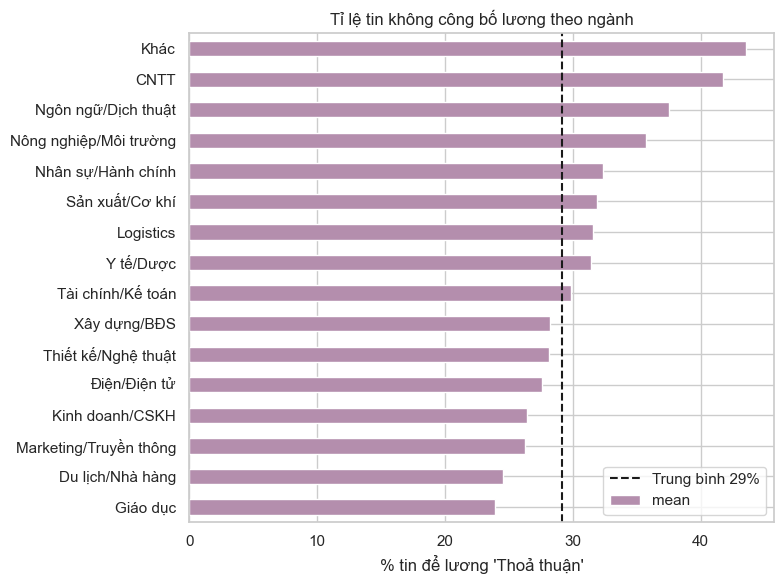

In [3]:
def rate(col, order=None):
    r = df.groupby(col, observed=True)["salary_negotiable"].agg(["mean", "size"])
    r["mean"] *= 100
    return r.reindex(order) if order is not None else r.sort_values("mean", ascending=False)

r_cat = rate("cat")
fig, ax = plt.subplots(figsize=(8, 6))
r_cat["mean"].sort_values().plot.barh(ax=ax, color="#b48ead")
ax.axvline(overall, ls="--", c="k", label=f"Trung bình {overall:.0f}%")
ax.set(xlabel="% tin để lương 'Thoả thuận'", ylabel="", title="Tỉ lệ tin không công bố lương theo ngành")
ax.legend()
savefig("q3_negotiable_by_category.png")

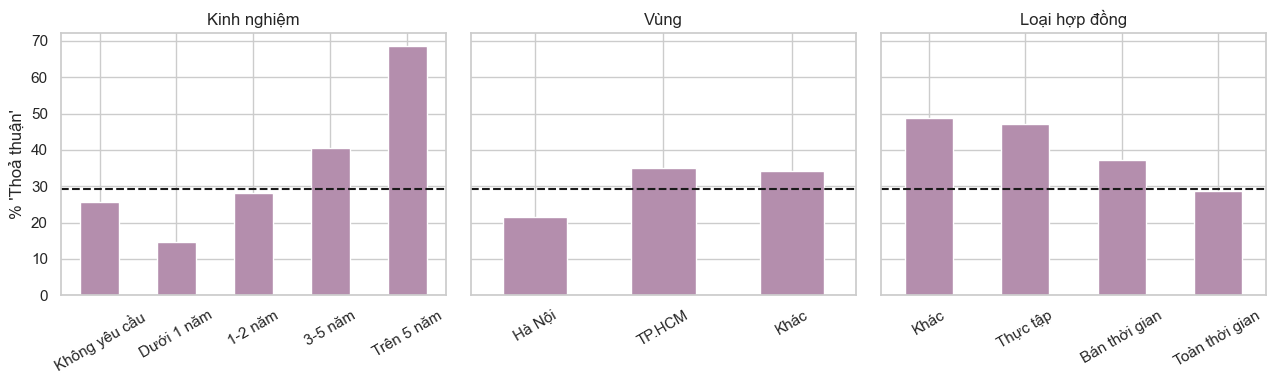

mean   size
kinh nghiệm Không yêu cầu   25.6   8994
            Dưới 1 năm      14.6   1777
            1-2 năm         28.1  19208
            3-5 năm         40.6   6290
            Trên 5 năm      68.6    188
vùng        Hà Nội          21.6  15315
            TP.HCM          35.0  12230
            Khác            34.2   8912
hợp đồng    Khác            48.6    259
            Thực tập        47.1    650
            Bán thời gian   37.3    657
            Toàn thời gian  28.5  34891

In [4]:
levels = [l for l in EXPERIENCE_LEVELS if l != "Không rõ"]
r_exp, r_reg, r_con = rate("experience_level", levels), rate("region", REGIONS), rate("contract_group")
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (r, t) in zip(axes, [(r_exp, "Kinh nghiệm"), (r_reg, "Vùng"), (r_con, "Loại hợp đồng")]):
    r["mean"].plot.bar(ax=ax, color="#b48ead")
    ax.axhline(overall, ls="--", c="k")
    ax.set(title=t, xlabel="", ylabel="% 'Thoả thuận'")
    ax.tick_params(axis="x", rotation=30)
savefig("q3_negotiable_by_exp_region_contract.png")
display(pd.concat({"kinh nghiệm": r_exp, "vùng": r_reg, "hợp đồng": r_con}).round(1))

## Kết luận

In [5]:
print(f"- {overall:.1f}% tin không công bố lương.")
print(f"- Ngành giấu lương nhiều nhất: {r_cat.index[0]} ({r_cat['mean'].iloc[0]:.0f}%), {r_cat.index[1]} ({r_cat['mean'].iloc[1]:.0f}%); "
      f"ít nhất: {r_cat.index[-1]} ({r_cat['mean'].iloc[-1]:.0f}%).")
print(f"- Theo kinh nghiệm: 'Không yêu cầu' {r_exp.loc['Không yêu cầu', 'mean']:.0f}% so với 'Trên 5 năm' {r_exp.loc['Trên 5 năm', 'mean']:.0f}%.")
best = tests["cramers_v"].idxmax()
print(f"- Tất cả các biến đều có p < 0.05: {bool((tests.p < 0.05).all())}; liên hệ mạnh nhất là '{best}' "
      f"(Cramér's V = {tests.loc[best, 'cramers_v']:.2f}; < 0.1 yếu, 0.1–0.3 vừa).")

- 29.2% tin không công bố lương.
- Ngành giấu lương nhiều nhất: Khác (44%), CNTT (42%); ít nhất: Giáo dục (24%).
- Theo kinh nghiệm: 'Không yêu cầu' 26% so với 'Trên 5 năm' 69%.
- Tất cả các biến đều có p < 0.05: True; liên hệ mạnh nhất là 'experience_level' (Cramér's V = 0.15; < 0.1 yếu, 0.1–0.3 vừa).


**Hạn chế chung:** dữ liệu chỉ từ TopCV (2025), là **lương đăng tuyển** (không phải lương thực nhận),
và ~29% tin không công bố lương. Kết luận chỉ mô tả thị trường tin tuyển dụng trên nền tảng này.

*Nhận xét trên được sinh tự động từ số liệu — thành viên phụ trách cần đọc lại và diễn giải bằng lời của mình.*